# STREAM: trajectory reconstruction and cell positions

This notebook reconstructs the Nestorowa cell differentiation trajectory using **STREAM 0.3.1** and exports the position of **every cell** along the inferred tree.

Run the cells **from top to bottom**. The original STREAM methods, parameters, input files and trajectory-distance calculations are retained.

**Inputs (unchanged):** `../Data/data_Nestorowa.tsv.gz`, `../Data/cell_label.tsv.gz`, and `../Data/cell_label_color.tsv.gz`.

**All generated output files:** `Results/STREAM_outputs/` (relative to the notebook working directory).

## 1. Set up STREAM and the output folder

Import STREAM, keep plots inside the notebook, and make one folder for the results. `plot_and_save` saves every Matplotlib figure produced by the plotting steps, without changing the plots themselves.

In [ ]:
# Show plots inside Jupyter instead of opening separate windows.
%matplotlib inline

In [1]:
from pathlib import Path  
import matplotlib.pyplot as plt  
import stream as st  

OUTPUT_DIR = Path("../Results") / "STREAM_outputs"  # One location for all output files.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # Create it if it does not exist.
print("Results folder:", OUTPUT_DIR.resolve())  # Show where files will be saved.


def plot_and_save(plot_function, name, *args, **kwargs):
    figures_before = set(plt.get_fignums())  # Note which figures are already open.
    result = plot_function(*args, **kwargs)  # Run the original STREAM function.
    new_figures = sorted(set(plt.get_fignums()) - figures_before)  # Find new figures.

    if not new_figures:  # Some plotting functions may reuse the current figure.
        if isinstance(result, plt.Figure):  # Check whether STREAM returned a figure.
            result.savefig(OUTPUT_DIR / (name + ".png"), dpi=200, bbox_inches="tight")
        else:
            print("No open Matplotlib figure was available to save for", name)
        return result  # Keep the original function's return value.

    for number, fig_id in enumerate(new_figures, start=1):  # Save each new figure.
        suffix = "" if len(new_figures) == 1 else f"_{number:02d}"  # Name multiple plots separately.
        filename = OUTPUT_DIR / f"{name}{suffix}.png"  # Put the file in the output folder.
        plt.figure(fig_id).savefig(filename, dpi=200, bbox_inches="tight")  # Save at good resolution.

    return result  # Leave figures open so Jupyter can display them.

print("STREAM version:", st.__version__)  # Confirm the installed STREAM version.

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/anndata/core/anndata.py:17: FutureWarning: pandas.core.index is deprecated and will be removed in a future version.  The public classes are available in the top-level namespace.
  from pandas.core.index import RangeIndex


Results folder: /home/eren/Results/STREAM_outputs
STREAM version: 0.3.1


## 2. Read the expression matrix and cell annotations

Load the expression data, then attach cell types and their display colors. Setting `workdir` tells STREAM where to save its own result files.

In [2]:
adata = st.read(  
    file_name="../Data/data_Nestorowa.tsv.gz",  
    workdir=str(OUTPUT_DIR.resolve())  
)
st.add_cell_labels(adata, file_name="../Data/cell_label.tsv.gz")  
st.add_cell_colors(adata, file_name="../Data/cell_label_color.tsv.gz")  
print(adata.shape)  # Check the number of cells and genes.

(1656, 4768)


## 3. Filter genes and select variable genes

Remove genes with too little expression, then select genes with varying expression across cells. The original filtering parameters are unchanged.

filter genes based on min_num_cells
after filtering out low-expressed genes: 
1656 cells, 4762 genes
No open Matplotlib figure was available to save for 01_gene_filtering


/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/anndata/core/anndata.py:1239: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_categorical(df_full[k]):


239 variable genes are selected


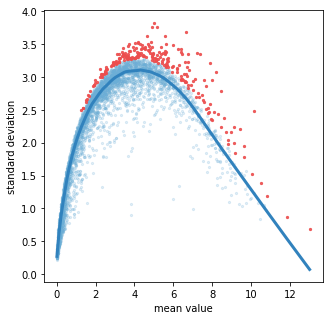

In [3]:
plot_and_save(  
    st.filter_genes, "01_gene_filtering", adata,
    min_num_cells=max(5, int(round(adata.shape[0] * 0.001))),  # Minimum expressing cells.
    min_pct_cells=None,  # Do not use an additional percentage threshold.
    expr_cutoff=1  # A gene counts as expressed above this value.
)
plot_and_save(st.select_variable_genes, "02_variable_gene_selection", adata)  # Select variable genes.

## 4. Reduce dimensions

Compress the gene-expression information into fewer dimensions to make trajectory reconstruction possible, then visualize the reduced data.

24 cpus are being used ...


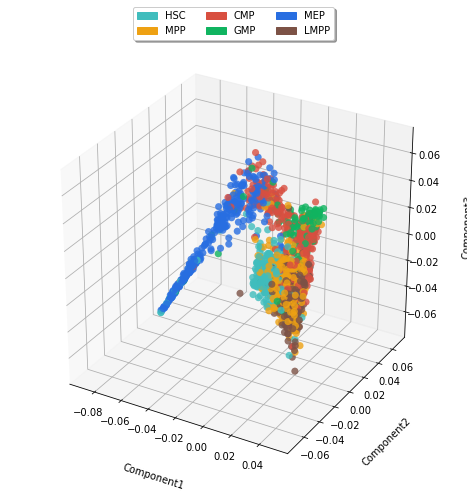

In [4]:
st.dimension_reduction(adata)  # Calculate the lower-dimensional representation.
plot_and_save(st.plot_dimension_reduction, "03_dimension_reduction", adata)  # Show the cells.

## 5. Construct the trajectory tree

First create a starting tree, then fit the elastic principal graph. Optimize its branches and extend the endpoints. These operations infer the branching structure from the cells.

Seeding initial elastic principal graph...
Clustering...
Affinity propagation ...


/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/sklearn/cluster/_affinity_propagation.py:154: FutureWarning: 'random_state' has been introduced in 0.23. It will be set to None starting from 1.0 (renaming of 0.25) which means that results will differ at every function call. Set 'random_state' to None to silence this warning, or to 0 to keep the behavior of versions <0.23.
  FutureWarning


The number of initial nodes is 27
Calculatng minimum spanning tree...
Number of initial branches: 13


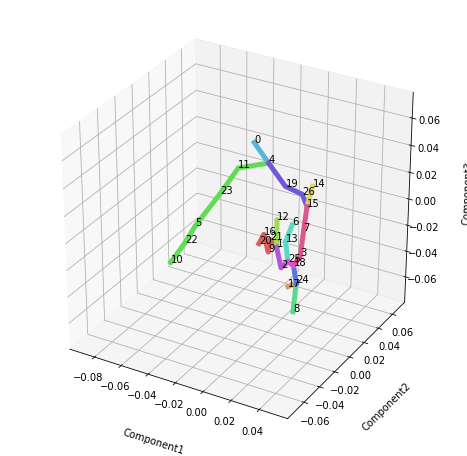

In [5]:
st.seed_elastic_principal_graph(adata)  # Create the starting graph.
plot_and_save(st.plot_branches, "04_seeded_branches", adata)  # Plot the starting branches.

epg_n_nodes is too small. It is corrected to the initial number of nodes plus incr_n_nodes
Learning elastic principal graph...
[1] "Constructing tree 1 of 1 / Subset 1 of 1"
[1] "Computing EPG with 57 nodes on 1656 points and 3 dimensions"
[1] "Using a single core"
Nodes = 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 
BARCODE	ENERGY	NNODES	NEDGES	NRIBS	NSTARS	NRAYS	NRAYS2	MSE	MSEP	FVE	FVEP	UE	UR	URN	URN2	URSD
2||57	0.0001008	57	56	51	2	0	0	6.104e-05	5.878e-05	0.9663	0.9676	3.586e-05	3.899e-06	0.0002222	0.01267	0
13.324 sec elapsed
[[1]]

Number of branches after learning elastic principal graph: 5


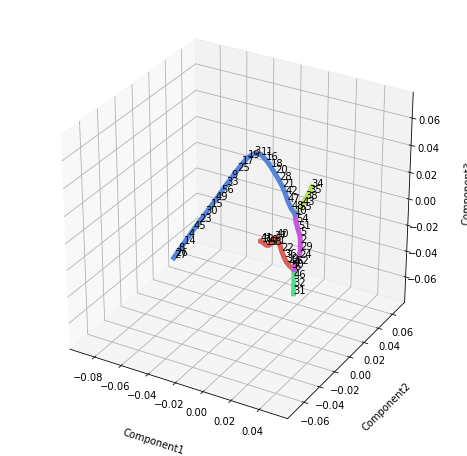

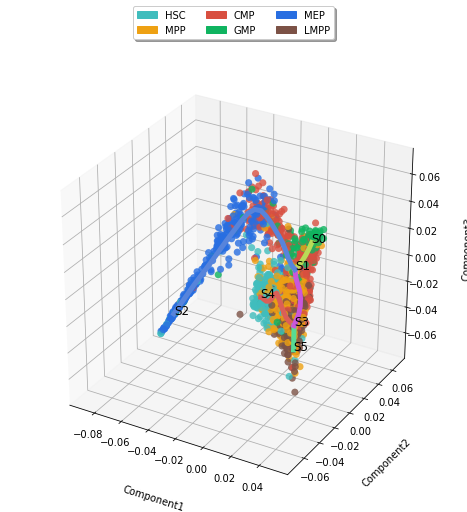

In [6]:
st.elastic_principal_graph(adata)  # Fit the elastic principal graph to the cells.
plot_and_save(st.plot_branches, "05_fitted_branches", adata)  # Plot the fitted tree.
plot_and_save(st.plot_branches_with_cells, "06_fitted_branches_cells", adata)  # Add cells to the tree.

Optimizing branching...
[1] "Constructing tree 1 of 1 / Subset 1 of 1"
[1] "Computing EPG with 87 nodes on 1656 points and 3 dimensions"
[1] "Using a single core"
Nodes = 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 
BARCODE	ENERGY	NNODES	NEDGES	NRIBS	NSTARS	NRAYS	NRAYS2	MSE	MSEP	FVE	FVEP	UE	UR	URN	URN2	URSD
2||87	6.702e-05	87	86	81	2	0	0	4.285e-05	4.116e-05	0.9764	0.9773	1.844e-05	5.73e-06	0.0004985	0.04337	0
4.358 sec elapsed
Number of branches after optimizing branching: 5


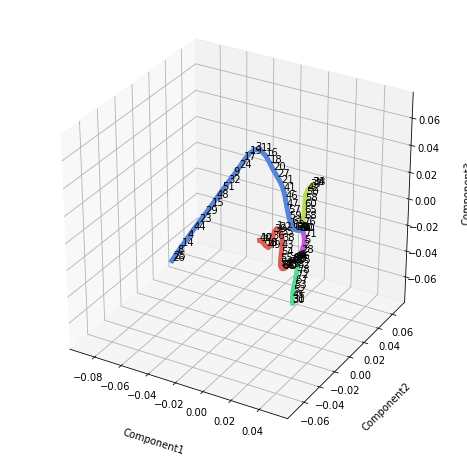

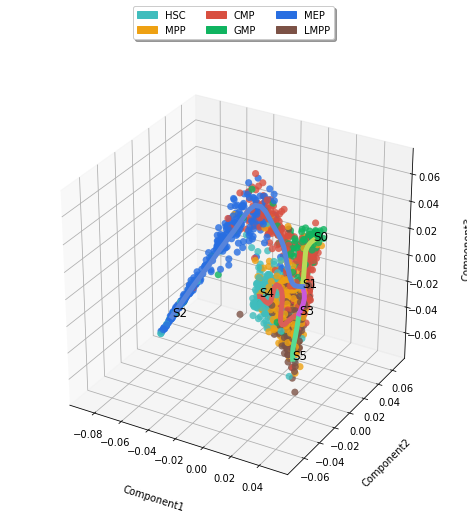

In [7]:
st.optimize_branching(adata, reset=True)  # Optimize the arrangement of branches.
plot_and_save(st.plot_branches, "07_optimized_branches", adata)  # Plot the optimized tree.
plot_and_save(st.plot_branches_with_cells, "08_optimized_branches_cells", adata)  # Show cell positions.

Extending leaves with additional nodes ...
Number of branches after extending leaves: 5


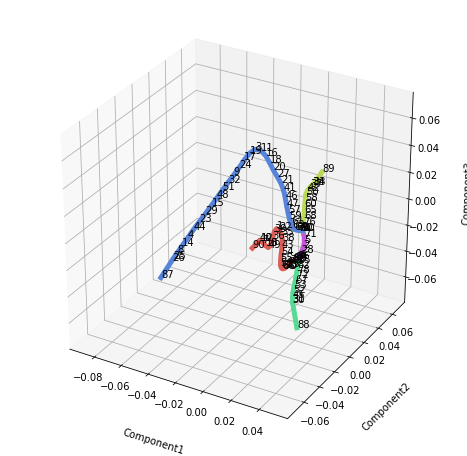

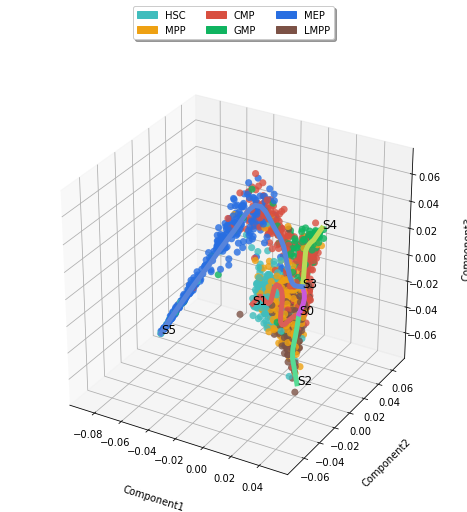

In [8]:
st.extend_elastic_principal_graph(adata)  # Extend tree endpoints using the data.
plot_and_save(st.plot_branches, "09_extended_branches", adata)  # Plot extended branches.
plot_and_save(st.plot_branches_with_cells, "10_extended_branches_cells", adata)  # Show their cells.

## 6. Visualize the final tree

Display the simplified tree, 2D cell plots, and STREAM subway maps. The analysis uses `S1` as its root, just like the original notebook.

The vertical order of sibling branches in a subway map is for display only. `preference=['S4','S5']` changes that order, not the inferred lineage.

Importing precomputed umap visualization ...


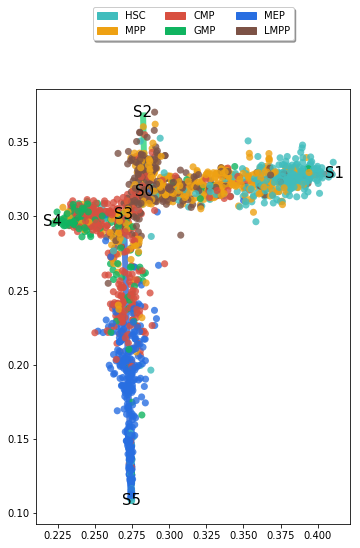

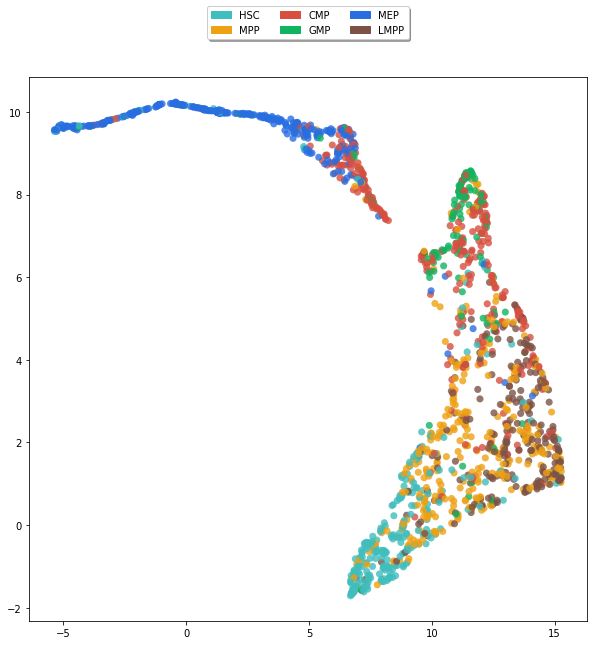

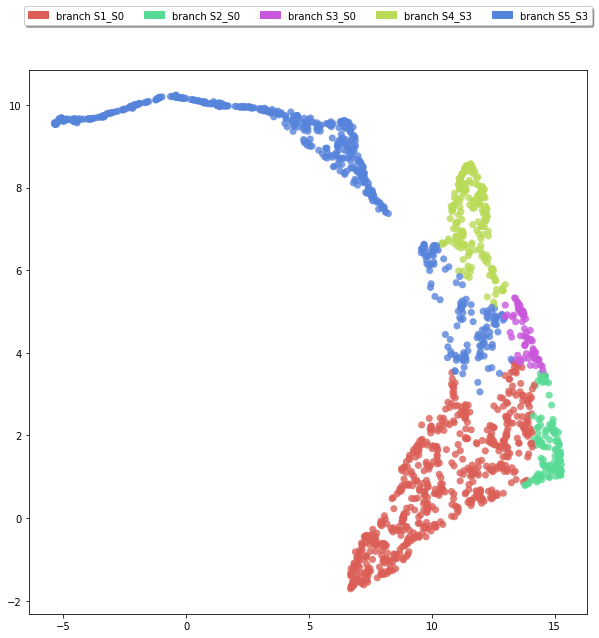

In [9]:
plot_and_save(st.plot_flat_tree, "11_flat_tree", adata)  # Draw the simplified tree.
plot_and_save(st.plot_visualization_2D, "12_visualization_2D", adata,
              use_precomputed=False)  # Calculate and show a 2D visualization.
plot_and_save(st.plot_visualization_2D, "13_visualization_2D_branches", adata,
              color_by="branch", fig_legend_ncol=6)  # Color cells by branch.

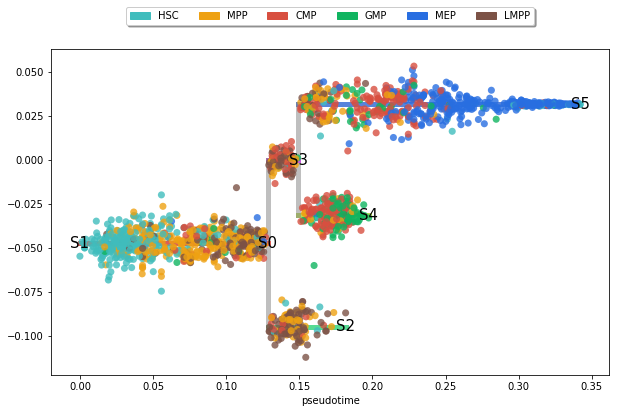

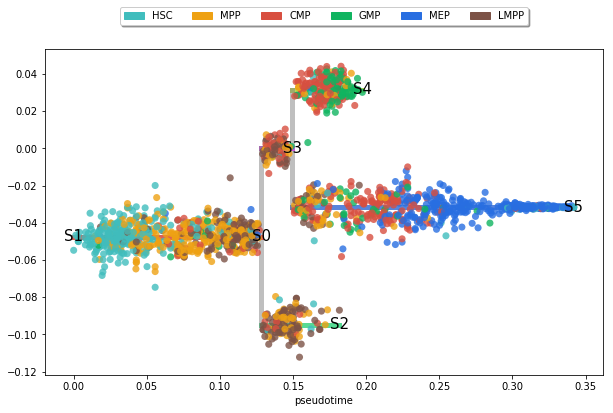

In [10]:
plot_and_save(st.subwaymap_plot, "14_subway_map", adata,
              percentile_dist=100, root="S1", fig_legend_ncol=6)  # Plot all cells from root S1.
plot_and_save(st.subwaymap_plot, "15_subway_map_reordered", adata,
              percentile_dist=100, root="S1", fig_legend_ncol=6,
              preference=["S4", "S5"])  # Change only the branch display order.

## 7. Find genes associated with differentiation

Detect genes that change along branches, differ between lineages, or distinguish terminal cell states. Then plot the results and selected marker genes.

In [11]:
st.detect_transistion_genes(adata, root="S1", preference=["S4", "S5"])  # Find branch-transition genes; STREAM spells this function "transistion".
st.detect_de_genes(adata, root="S1", preference=["S4", "S5"])  # Find differentially expressed genes.
st.detect_de_genes(adata, root="S1", preference=["S4", "S5"])  # Repeat the call as in the original notebook (usually unnecessary).
st.detect_leaf_genes(adata, root="S1", preference=["S4", "S5"])  # Find genes associated with terminal branches.

Minimum number of cells expressing genes: 5
Minimum number of cells expressing genes: 5
Importing precomputed scaled gene expression matrix ...
Minimum number of cells expressing genes: 5
Importing precomputed scaled gene expression matrix ...
Minimum number of cells expressing genes: 5
Importing precomputed scaled gene expression matrix ...


/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

...

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:169: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_grouped = np.array([x_flat[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_posthocs.py:185: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  x_ranks_grouped = np.array([x_ranks[j:j + x_lens[i]] for i, j in enumerate(x_lens_cumsum)])
/home/eren/miniforge3/envs/env_stream_03/lib/python3.6/site-packages/stream/scikit_postho

,zscore,H_statistic,H_pvalue,S1S0_pvalue,S3S4_pvalue,S3S5_pvalue,S0S2_pvalue
Mfsd2b,1.72663,809.244,4.27982e-175,4.76169e-210,3.39858e-118,Null,1.80633e-105
Gata1,1.72564,760.536,1.56622e-164,1.17325e-187,1.05915e-108,Null,1.02264e-99
Mpl,1.68169,754.626,2.99574e-163,Null,1.80422e-146,3.20442e-180,2.05186e-53
Vamp5,1.56731,720.931,6.07203e-156,2.13905e-132,3.39236e-136,Null,2.16952e-107
Epx,1.72955,716.155,6.59242e-155,1.32885e-197,Null,1.90727e-173,2.40849e-97
...,...,...,...,...,...,...,...
Xylt2,-1.6981,11.8332,0.0079771,0.00981223,0.00482538,0.00482538,Null
Zfp239,-1.67199,11.8204,0.00802443,0.00838468,0.00478199,0.00478199,Null
P2ry12,1.66265,11.7859,0.00815362,0.00402936,0.00632779,0.00402936,Null
Fut10,-1.62478,11.701,0.00848071,0.00771248,0.00771248,0.00566449,Null


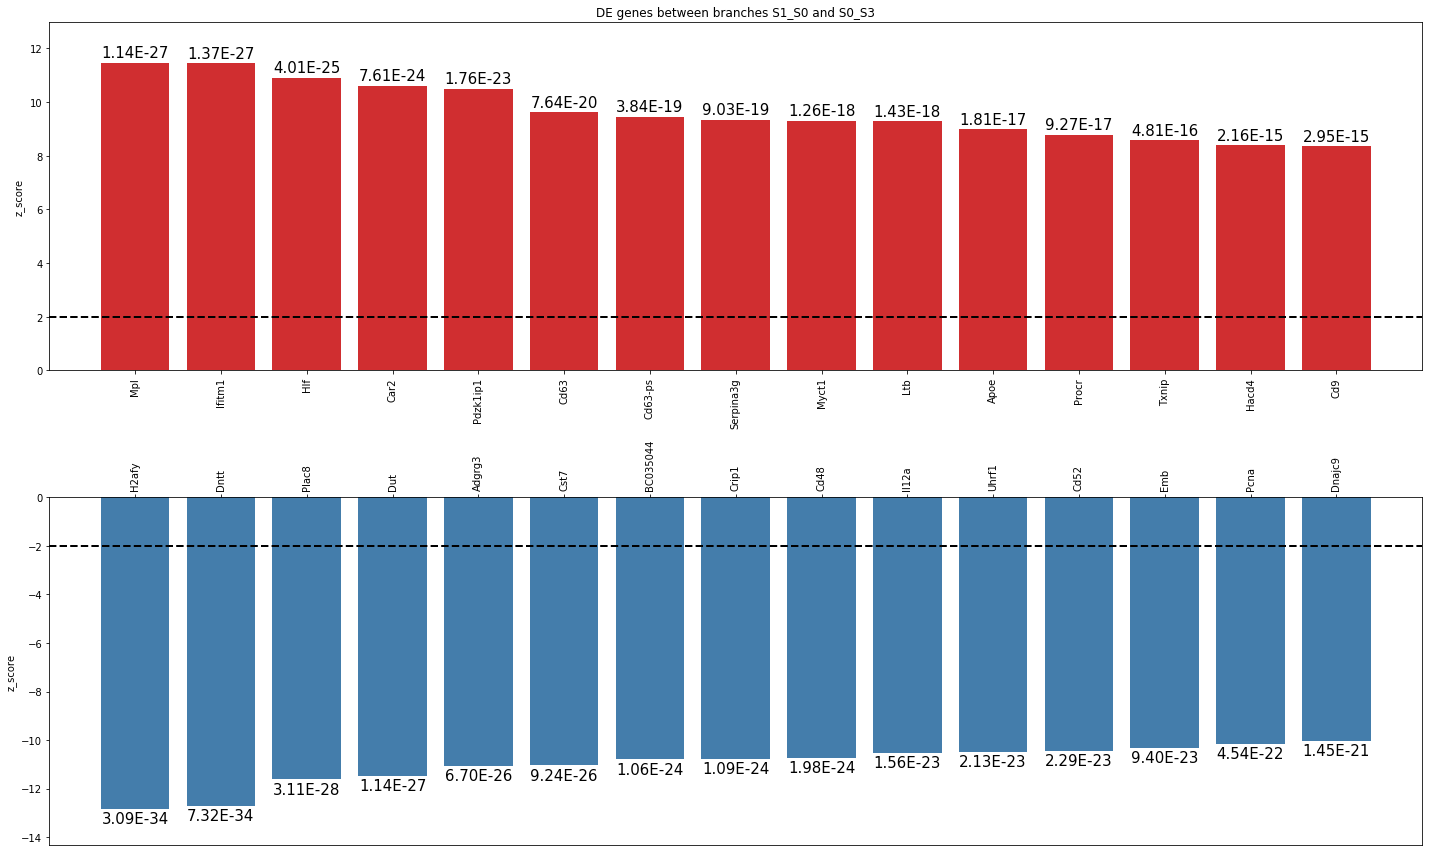

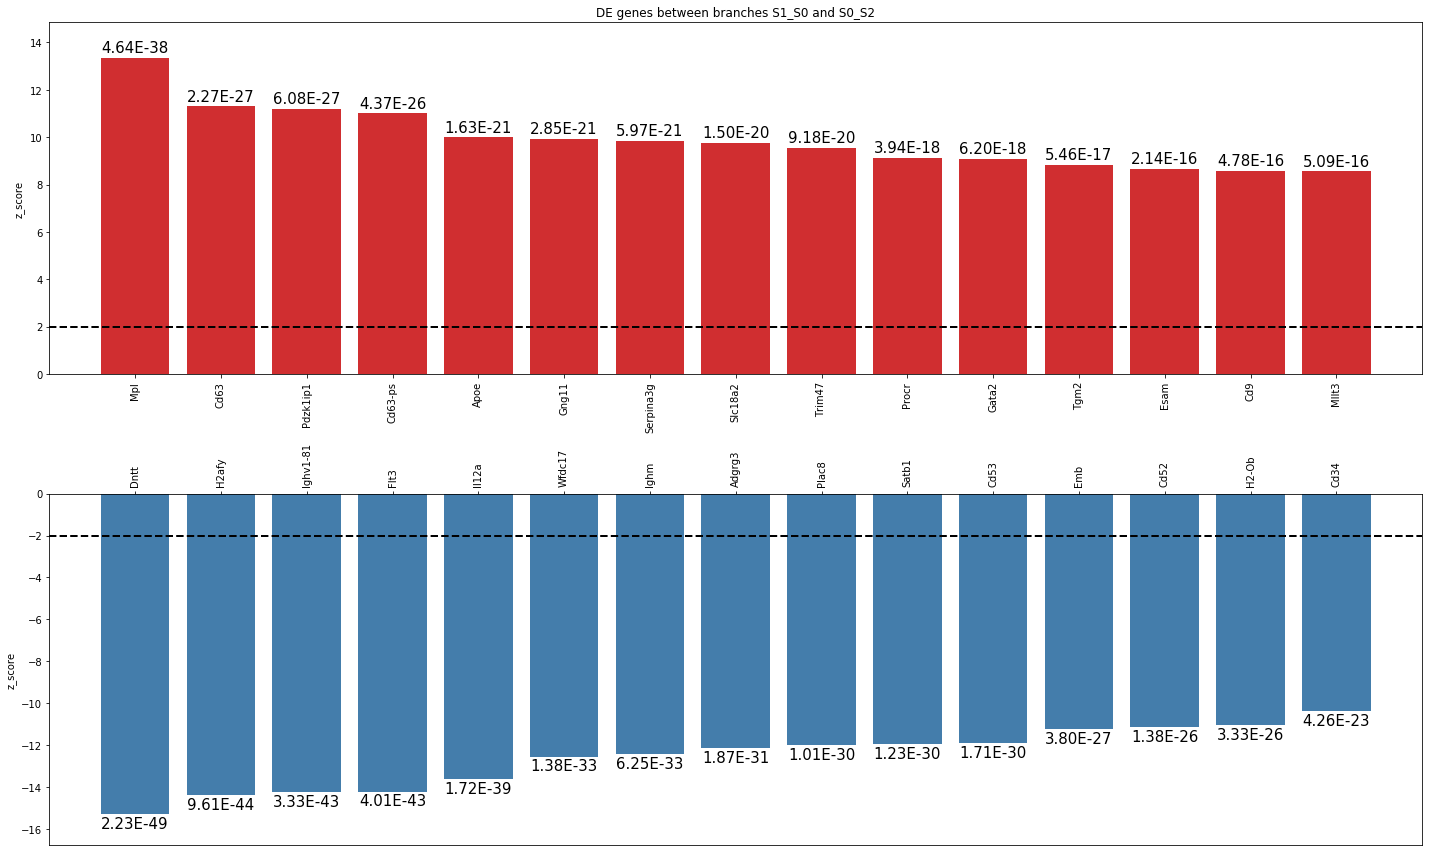

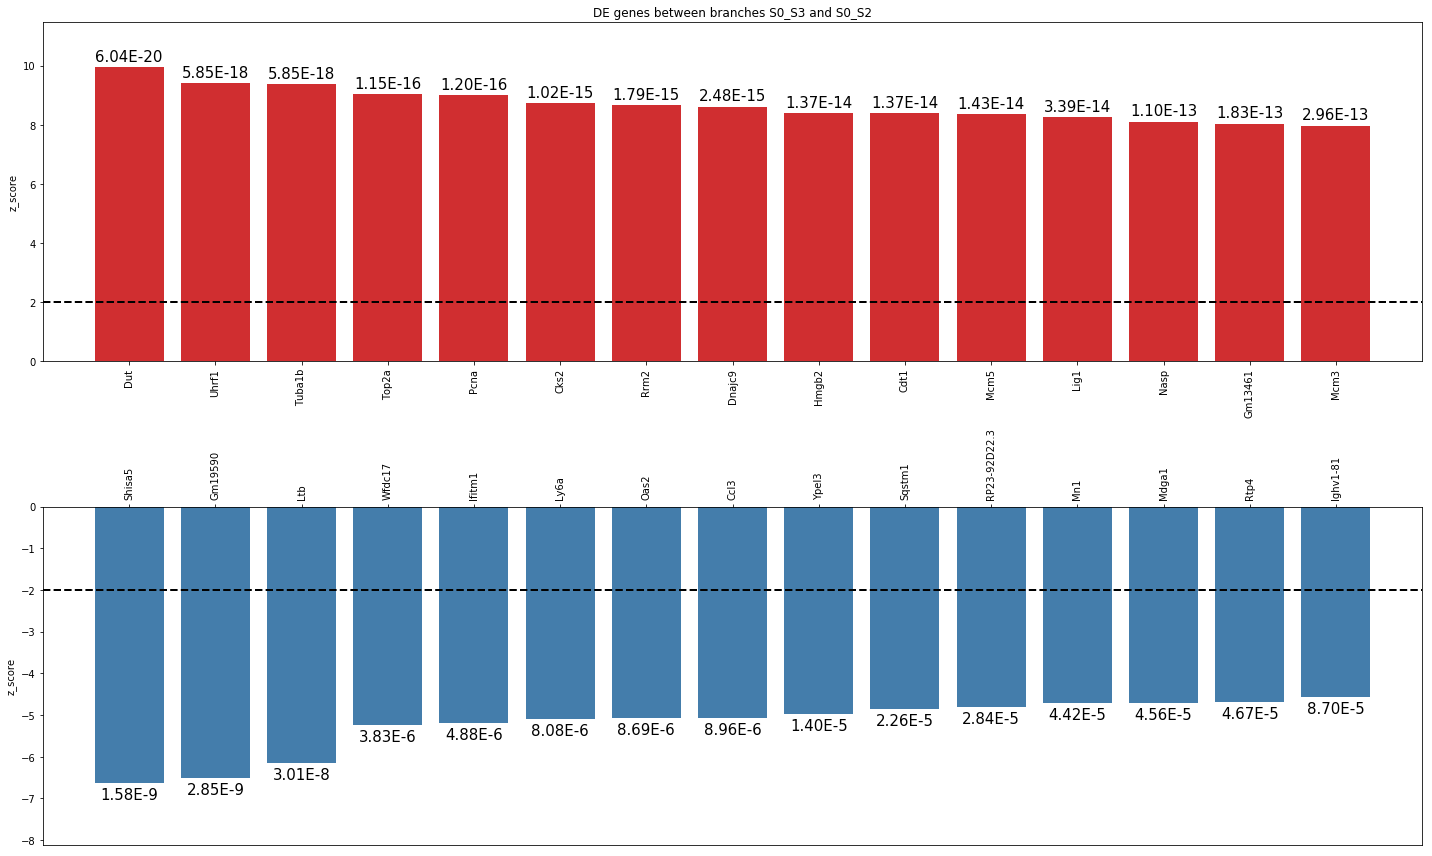

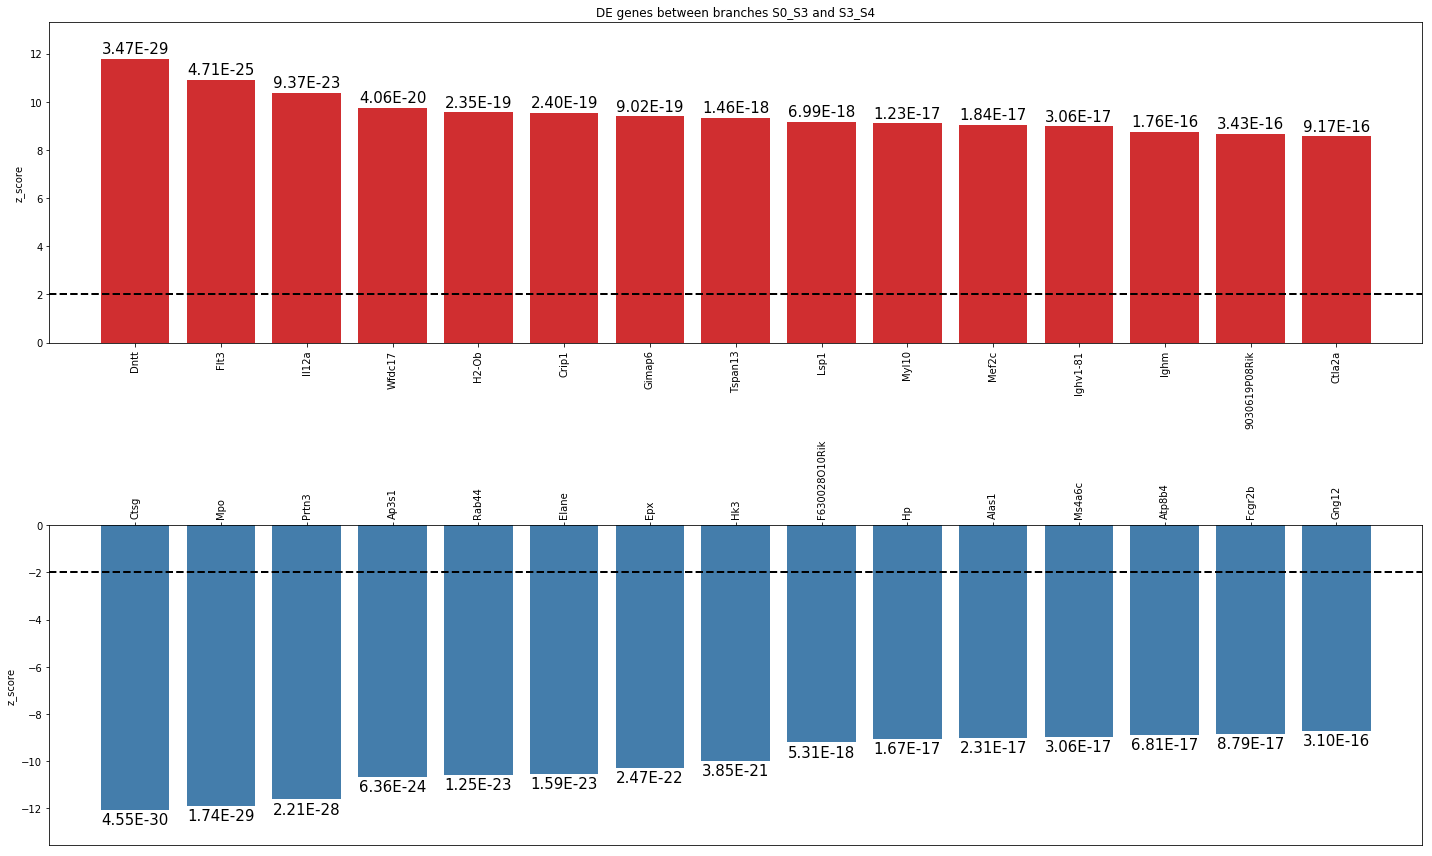

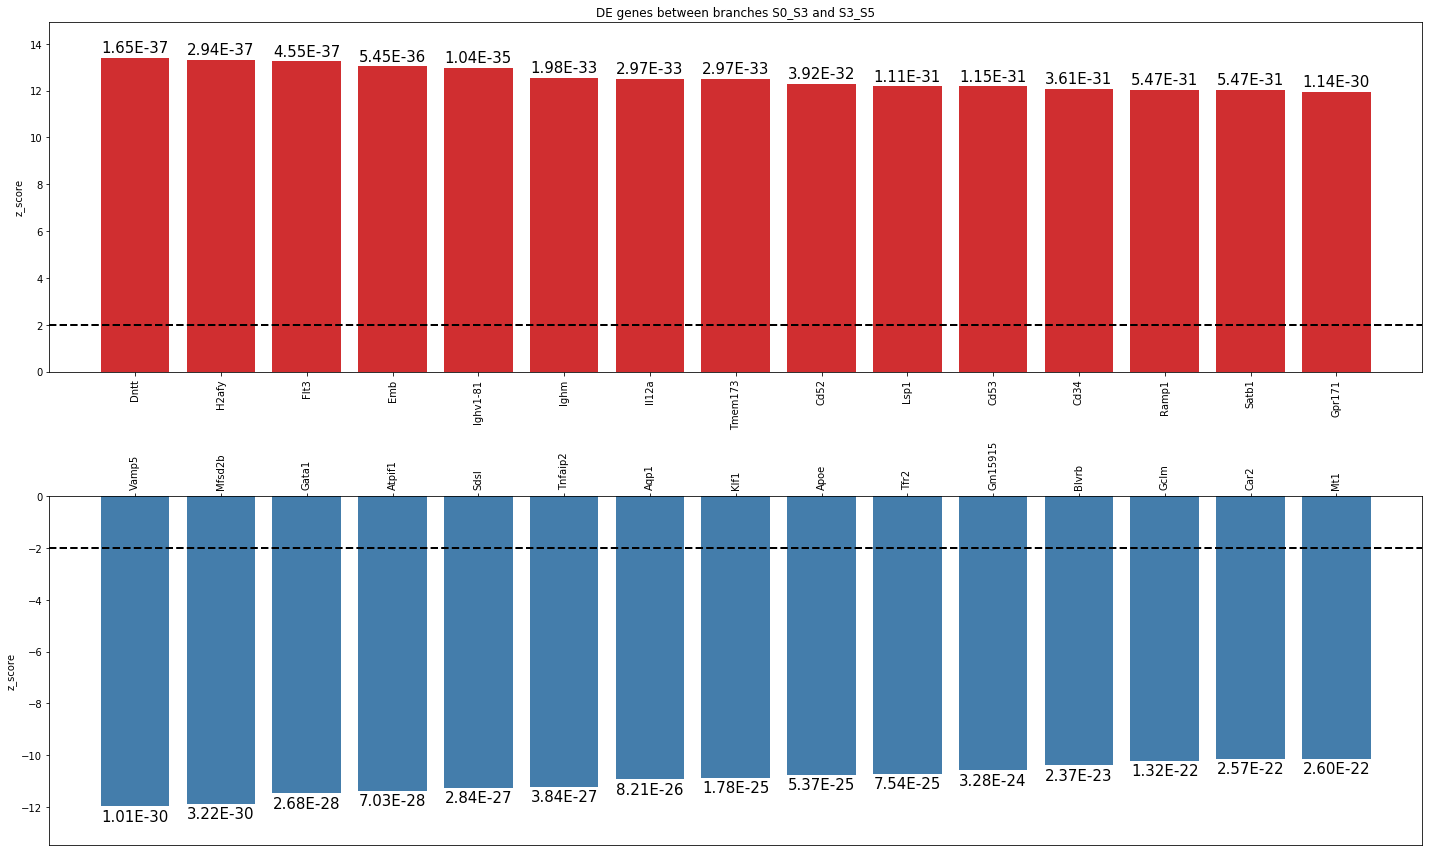

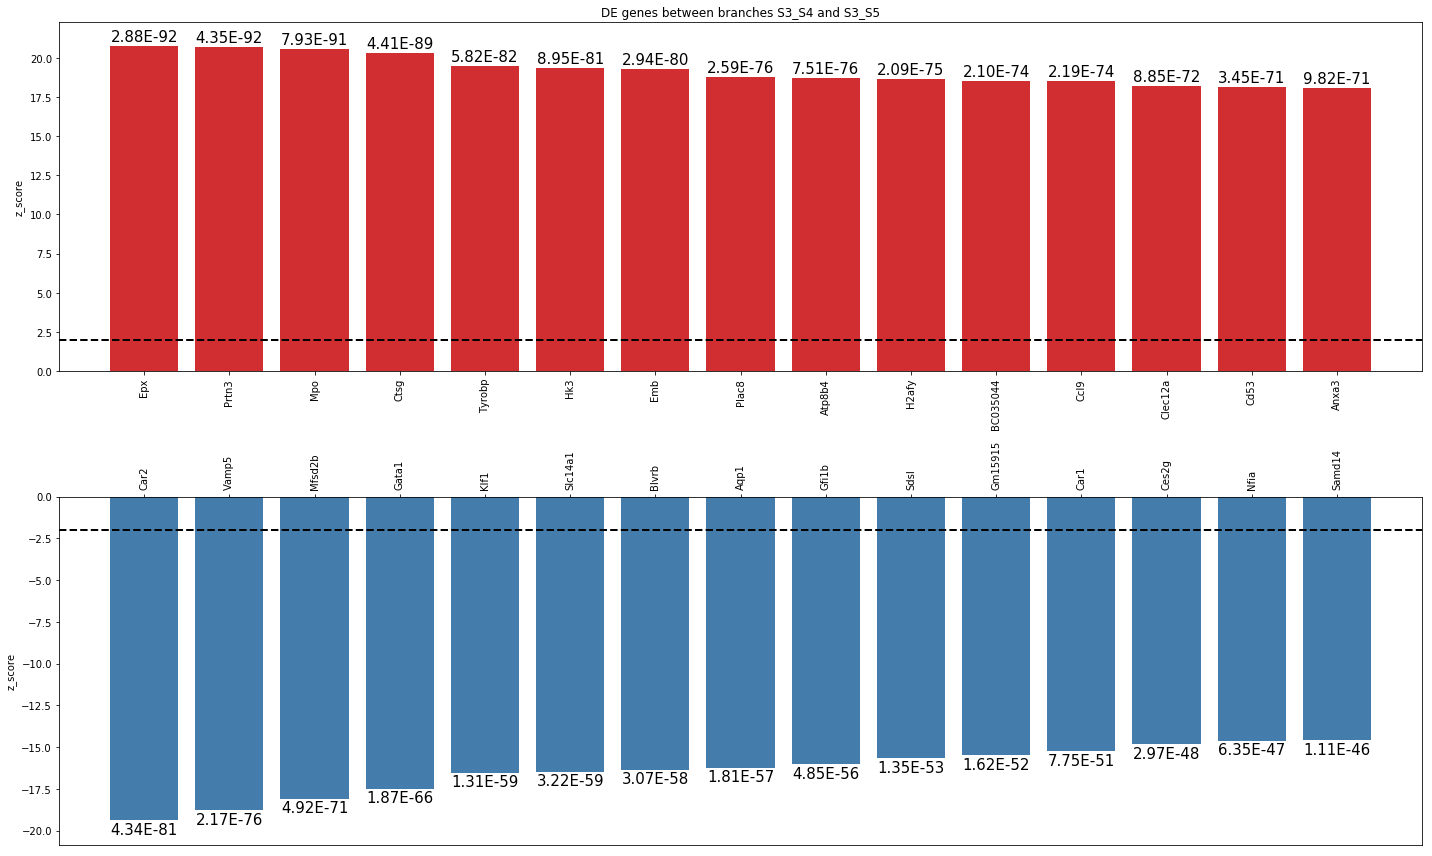

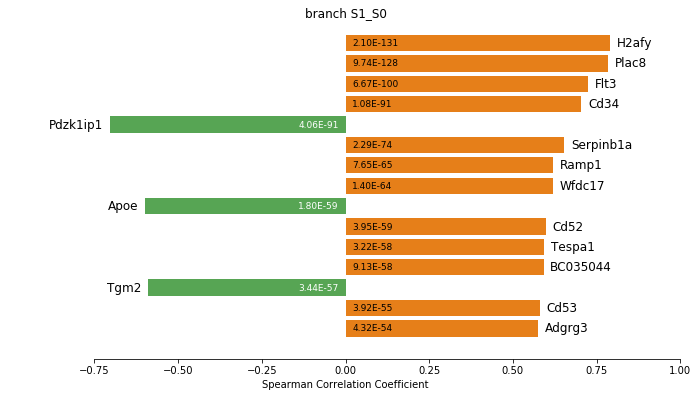

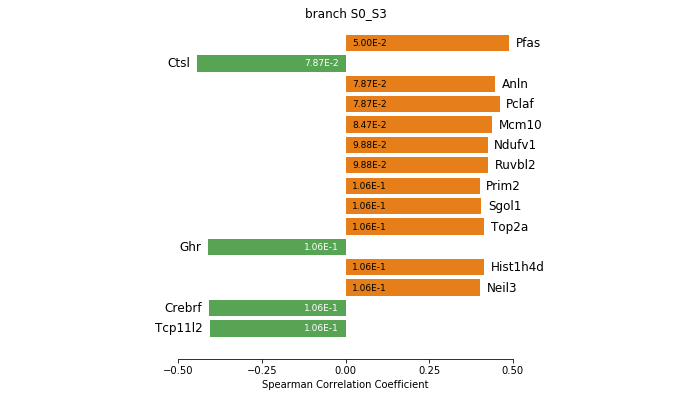

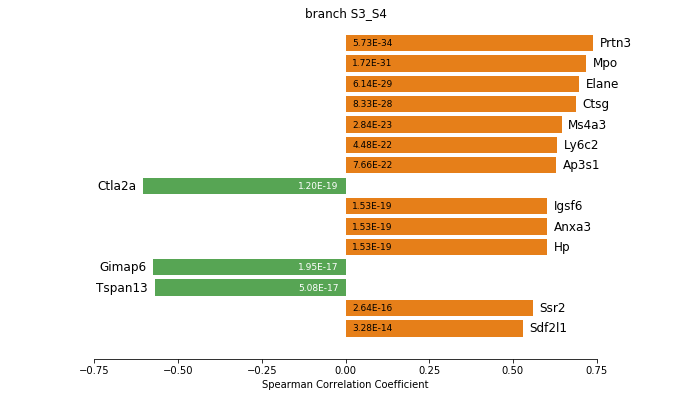

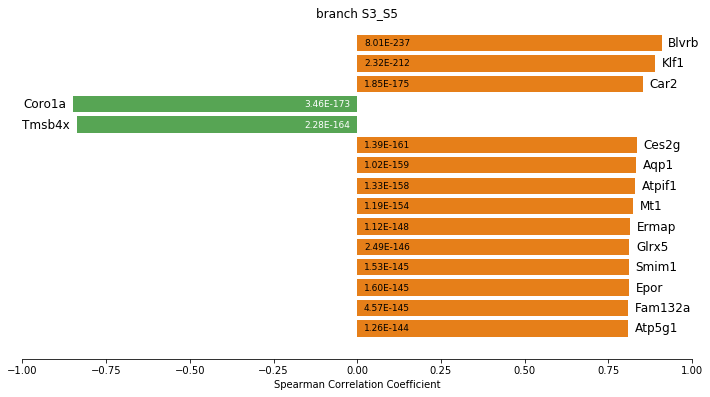

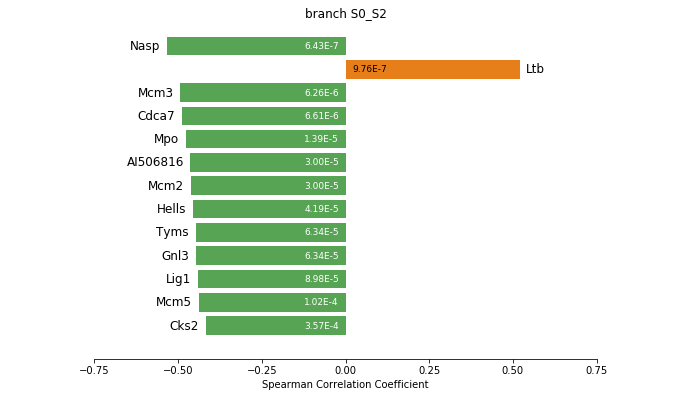

In [12]:
plot_and_save(st.plot_de_genes, "16_differential_genes", adata)  # Plot differential genes.
plot_and_save(st.plot_transition_genes, "17_transition_genes", adata)  # Plot transition genes.
adata.uns["leaf_genes_all"]  # Display the leaf-gene results kept by STREAM.

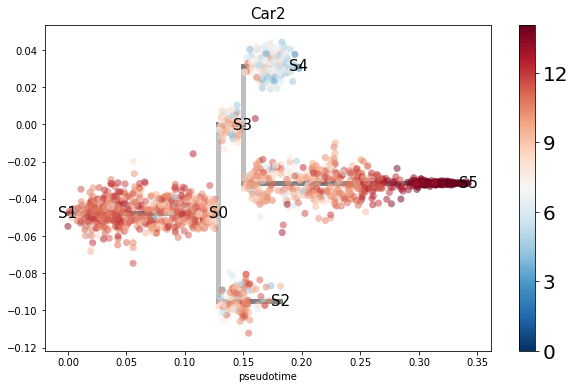

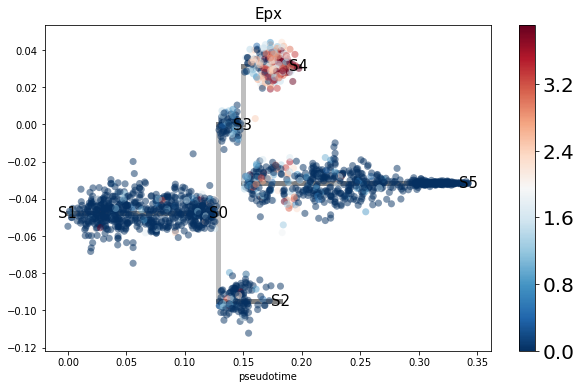

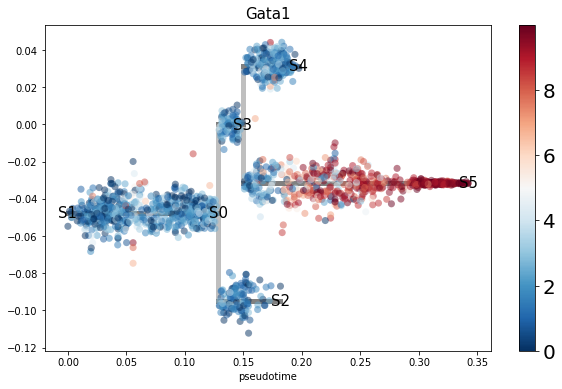

In [13]:
plot_and_save(  # Plot example gene-expression patterns on the trajectory.
    st.subwaymap_plot_gene, "18_marker_gene_subway_maps", adata,
    percentile_dist=100, root="S1", preference=["S4", "S5"],
    genes=["Gata1", "Car2", "Epx"]  # Keep the original example genes.
)

## 8. Save the full STREAM result

Save the annotated dataset and reconstructed trajectory. STREAM writes it into the output directory set in Step 2.

In [14]:
st.write(adata)  # Save the full result as Results/STREAM_outputs/stream_result.pkl.

## 9. Export the position of **every cell** on the trajectory

These exports use the already-fitted STREAM tree. **No cells are selected or removed here.**

We will:
1. Read the tree and check the cell projection columns.
2. Record the length of each branch.
3. Calculate each cell's distance along the tree to every state.
4. Keep all cell annotations and create a long-format distance table.
5. Save four CSV files in `Results/STREAM_outputs/`.

Distances are **along the tree**, not Euclidean distances between cells in a 2D plot.

### 9A. Read the tree and validate its states

STREAM stores a small tree whose nodes are labeled `S0`, `S1`, and so on. This step checks that the tree and cell-position data are ready.

In [15]:
# Export trajectory information for ALL cells 
import os
import ast
import numpy as np
import pandas as pd
import networkx as nx

# Use the fitted tree from STREAM.
flat_tree = adata.uns['flat_tree']
# Copy all cell-level metadata.
cell_obs = adata.obs.copy()

# Identify columns required to locate each cell.
required = ['branch_id', 'branch_lam']
# Check which required columns are absent.
missing = [x for x in required if x not in cell_obs.columns]
# Stop if STREAM did not compute cell positions.
if missing:
    raise KeyError('Missing STREAM cell projection columns: ' + str(missing))

# STREAM's tree nodes have labels such as S0, S1, S2 ...
# Translate tree node IDs into S0, S1, ... labels.
node_to_state = {n: str(attrs.get('label', n)) for n, attrs in flat_tree.nodes(data=True)}
# Create the reverse lookup.
state_to_node = {state: node for node, state in node_to_state.items()}
# Reject duplicate state labels.
if len(node_to_state) != len(state_to_node):
    raise ValueError('Some STREAM tree nodes have duplicate state labels.')

# List the states in a stable order.
states = sorted(state_to_node)
# Show the states found in the tree.
print('STREAM states:', states)

# The branch_id is an ordered pair; branch_lam measures the position
# along that branch starting from branch_id[0].
# Standardize a branch identifier as a pair of nodes.
def read_branch_id(value):
    # Parse branch identifiers stored as text.
    if isinstance(value, str):
        value = ast.literal_eval(value)
    # Accept only node pairs.
    if isinstance(value, (tuple, list, np.ndarray)) and len(value) == 2:
        # Return the branch endpoints.
        return tuple(value)
    # Reject invalid branch identifiers.
    raise ValueError('Unexpected branch_id: ' + str(value))

STREAM states: ['S0', 'S1', 'S2', 'S3', 'S4', 'S5']


### 9B. Record tree branches

Read each branch's endpoints and length. The same branch can be listed in either direction when locating a cell.

In [16]:
# Find the tree edge and its length for each STREAM branch identifier.
# Store both directions of each branch.
branches = {}
# Collect branch information for the CSV export.
edge_records = []
# Examine each edge of the STREAM tree.
for u, v, attrs in flat_tree.edges(data=True):
    # Read the branch identifier.
    branch_id = read_branch_id(attrs.get('id', (u, v)))
    # Read the branch length.
    length = attrs.get('len', attrs.get('length'))
    # Check that the branch length is present.
    if length is None:
        raise KeyError('Missing len/length on flat_tree edge ' + str((u, v)))
    # Read the branch length.
    length = float(length)
    # Only positive branch lengths are valid.
    if length <= 0:
        raise ValueError('Nonpositive tree branch length for ' + str((u, v)))
    # Confirm the identifier matches its tree edge.
    if set(branch_id) != set((u, v)):
        raise ValueError('Edge ID and flat_tree endpoints differ for ' + str((u, v)) +
                         '. Check the STREAM version before computing distances.')
    # Keep the forward direction.
    branches[branch_id] = (branch_id[0], branch_id[1], length)
    # Also support the reverse direction.
    branches[branch_id[::-1]] = (branch_id[1], branch_id[0], length)
    # Store the edge for the output table.
    edge_records.append({
        'from_state': node_to_state[u],
        'to_state': node_to_state[v],
        'branch_id': str(branch_id),
        'branch_length': length
    })

### 9C. Calculate paths between states

For each state, find the shortest distances along the tree to all other nodes.

In [17]:
# For a cell projected at distance lam along an edge (u, v), the
# shortest distance along the tree to node s is:
# min(lam + d(u,s), (edge_length-lam) + d(v,s)).
# Precalculate shortest tree paths to every state.
shortest = {
    state: nx.single_source_dijkstra_path_length(flat_tree, node, weight='len')
    for state, node in state_to_node.items()
}

### 9D. Calculate distances for every cell

Each cell lies somewhere along a branch. Its distance to a state is the shorter tree route through either end of that branch.

In [18]:
# Store one result per cell.
records = []
# Process each cell without filtering.
for cell_id, row in cell_obs.iterrows():
    # Read the branch identifier.
    branch_id = read_branch_id(row['branch_id'])
    # Check that the branch exists.
    if branch_id not in branches:
        raise KeyError('Cell ' + str(cell_id) + ' has unknown branch_id: ' + str(branch_id))

    # Get the branch endpoints and length.
    u, v, edge_length = branches[branch_id]
    # Read the distance from the start of the branch.
    lam = float(row['branch_lam'])
    # Reject an invalid cell position.
    if not np.isfinite(lam):
        raise ValueError('Invalid branch_lam for cell ' + str(cell_id))
    # Allow small rounding errors.
    tolerance = max(1e-6, edge_length * 1e-4)
    # Check whether the cell lies on its branch.
    if lam < -tolerance or lam > edge_length + tolerance:
        raise ValueError('branch_lam outside branch length for cell ' + str(cell_id))
    # Correct tiny numerical overshoots.
    lam = min(max(lam, 0.0), edge_length)

    # Record the cell position and its branch.
    result = {
        'cell_id': str(cell_id),
        'branch_id': str(branch_id),
        'branch_from': node_to_state[u],
        'branch_to': node_to_state[v],
        'branch_lam': lam,
        'branch_length': edge_length
    }
    # Calculate distance from this cell to every state.
    for state in states:
        # Take the shorter route through either branch endpoint.
        result['distance_to_' + state] = min(
            lam + shortest[state][u],
            edge_length - lam + shortest[state][v]
        )
    # Save this cell’s measurements.
    records.append(result)

# Build a table with one row per cell.
cell_distances = pd.DataFrame.from_records(records)

### 9E. Keep annotations and find the nearest state

Merge the distances with the original cell annotations, then record each cell's nearest state.

In [19]:
# Retain ALL existing cell-level metadata as well (cell type, branch_dist,
# any calculated pseudotimes, and so on). No cells are excluded.
# Retain all other annotations and pseudotimes.
other_meta = cell_obs.drop(columns=['branch_id', 'branch_lam'], errors='ignore').copy()
# Ensure cell IDs can be matched as strings.
other_meta.index = other_meta.index.astype(str)
# Name the cell ID column.
other_meta.index.name = 'cell_id'
# Build a table with one row per cell.
cell_distances = cell_distances.merge(
    other_meta.reset_index(),
    on='cell_id',
    how='left',
    validate='one_to_one'
)

# Identify the distance-to-state columns.
distance_columns = ['distance_to_' + state for state in states]
# Find the nearest trajectory state for each cell.
cell_distances['nearest_state'] = cell_distances[distance_columns].idxmin(axis=1).str.replace('distance_to_', '', regex=False)
# Save the distance to that state.
cell_distances['distance_to_nearest_state'] = cell_distances[distance_columns].min(axis=1)

### 9F. Build the long-format distance table

The long table has one row for each combination of cell and state. It is useful for comparing cells' distances to S0, S1, and other states.

In [20]:
# Long-format table: every cell appears once for EACH state (not selected).
# Select metadata to repeat in the long table.
long_info = ['cell_id', 'nearest_state', 'branch_from', 'branch_to', 'branch_lam']
# Include optional metadata only if it exists.
long_info += [c for c in ['branch_dist', 'label', 'S1_pseudotime'] if c in cell_distances.columns]
# Create one row per cell per state.
long_distances = cell_distances.melt(
    id_vars=long_info,
    value_vars=distance_columns,
    var_name='state',
    value_name='distance_along_tree'
)
# Remove the column prefix from state labels.
long_distances['state'] = long_distances['state'].str.replace('distance_to_', '', regex=False)
# Create one row per cell per state.
long_distances = long_distances.sort_values(
    ['state', 'distance_along_tree', 'cell_id'], kind='mergesort'
)
# Give each cell a rank within each state.
long_distances['rank_for_state'] = long_distances.groupby('state').cumcount() + 1
# Create one row per cell per state.
long_distances = long_distances.reset_index(drop=True)

### 9G. Save all trajectory CSV files

Save the cell-level distances, long-format distances, tree nodes and tree edges into `Results/STREAM_outputs/`. Final checks confirm that all cells are included.

In [21]:
# Export graph geometry too, to document the six STREAM state positions.
# Create the table of state nodes.
node_table = pd.DataFrame([
    {'state': state, 'node_id': str(node), 'degree': int(flat_tree.degree(node))}
    for state, node in state_to_node.items()
]).sort_values('state')
# Create the table of tree edges.
edge_table = pd.DataFrame(edge_records)

# Use the same output folder as the STREAM result.
out_dir = str(OUTPUT_DIR)
# Make sure the output directory exists.
os.makedirs(out_dir, exist_ok=True)
# Save the complete per-cell table.
cell_distances.to_csv(os.path.join(out_dir, 'all_cells_trajectory.csv'), index=False)
# Save one row for each cell and state.
long_distances.to_csv(os.path.join(out_dir, 'all_cells_distances_long.csv'), index=False)
# Save the state node table.
node_table.to_csv(os.path.join(out_dir, 'tree_nodes.csv'), index=False)
# Save the branch table.
edge_table.to_csv(os.path.join(out_dir, 'tree_edges.csv'), index=False)

# Confirm each cell appears once.
assert cell_distances['cell_id'].is_unique
# Confirm no cells were removed.
assert len(cell_distances) == adata.n_obs
# Confirm every cell has a row for each state.
assert len(long_distances) == adata.n_obs * len(states)

# Report the export size.
print('Exported', len(cell_distances), 'cells and', len(states), 'trajectory states.')
# Confirm no selection threshold was applied.
print('Every cell is included; no closest-cell count or distance threshold was applied.')
# Show the final export directory.
print('Files saved in:', os.path.abspath(out_dir))
# Preview a few cell distances.
print(cell_distances[['cell_id', 'branch_from', 'branch_to'] + distance_columns].head())

Exported 1656 cells and 6 trajectory states.
Every cell is included; no closest-cell count or distance threshold was applied.
Files saved in: /home/eren/Results/STREAM_outputs
      cell_id branch_from branch_to  distance_to_S0  distance_to_S1  \
0    HSPC_025          S1        S0        0.019148        0.109204   
1    HSPC_031          S1        S0        0.022864        0.105489   
2    HSPC_037          S2        S0        0.015241        0.143593   
3  LT-HSC_001          S1        S0        0.091765        0.036587   
4    HSPC_001          S1        S0        0.085526        0.042826   

   distance_to_S2  distance_to_S3  distance_to_S4  distance_to_S5  
0        0.072472        0.040163        0.088190        0.232876  
1        0.076187        0.043879        0.091905        0.236591  
2        0.038082        0.036256        0.084282        0.228969  
3        0.145089        0.112781        0.160807        0.305493  
4        0.138850        0.106541        0.154567        

## 10. Output files

After the notebook runs, look in `Results/STREAM_outputs/` for:

- **`stream_result.pkl`** — STREAM's saved annotated dataset and fitted trajectory.
- **`all_cells_trajectory.csv`** — One row per cell, with distances to all states.
- **`all_cells_distances_long.csv`** — One row per cell per state.
- **`tree_nodes.csv`** and **`tree_edges.csv`** — The tree's states and branch lengths.
- **`.png` figures** — Trajectory, cell and gene plots where STREAM leaves the Matplotlib figures available.

The original three input files are read from `../Data/` and are not changed.

In [22]:
files = sorted(OUTPUT_DIR.rglob("*"))  # List files created in the results directory.
for path in files:  # Print one path per output file.
    if path.is_file():  # Ignore any subdirectories.
        print(path)  # Display the output filename.

../Results/STREAM_outputs/02_variable_gene_selection.png
../Results/STREAM_outputs/03_dimension_reduction.png
../Results/STREAM_outputs/04_seeded_branches.png
../Results/STREAM_outputs/05_fitted_branches.png
../Results/STREAM_outputs/06_fitted_branches_cells.png
../Results/STREAM_outputs/07_optimized_branches.png
../Results/STREAM_outputs/08_optimized_branches_cells.png
../Results/STREAM_outputs/09_extended_branches.png
../Results/STREAM_outputs/10_extended_branches_cells.png
../Results/STREAM_outputs/11_flat_tree.png
../Results/STREAM_outputs/12_visualization_2D.png
../Results/STREAM_outputs/13_visualization_2D_branches.png
../Results/STREAM_outputs/14_subway_map.png
../Results/STREAM_outputs/15_subway_map_reordered.png
../Results/STREAM_outputs/16_differential_genes_01.png
../Results/STREAM_outputs/16_differential_genes_02.png
../Results/STREAM_outputs/16_differential_genes_03.png
../Results/STREAM_outputs/16_differential_genes_04.png
../Results/STREAM_outputs/16_differential_genes_0